# GRIN Rod Lens

A gradient-index (GRIN) rod lens has flat faces. It focuses because its index falls off with distance from the axis. For the profile

$$n(r) = n_0 \left(1 - \tfrac{A}{2} r^2\right),$$

paraxial rays follow sinusoids with period (pitch) $P = 2\pi/\sqrt{A}$. A quarter-pitch rod focuses a collimated beam onto its exit face. Here the rod is modeled with `GradientMaterial`, whose Gradient 3 coefficient is $n_{r2} = -n_0 A / 2$.

In [1]:
import numpy as np

from optiland import optic
from optiland.analysis import SpotDiagram
from optiland.materials import GradientMaterial

In [2]:
class GrinRod(optic.Optic):
    """Quarter-pitch GRIN rod lens, focusing at its exit face."""

    def __init__(self, n0=1.6, A=0.01, pitch_fraction=0.25):
        super().__init__()
        length = pitch_fraction * 2 * np.pi / np.sqrt(A)
        rod = GradientMaterial(n0=n0, nr2=-n0 * A / 2)

        self.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
        self.surfaces.add(
            index=1, radius=np.inf, thickness=length, material=rod, is_stop=True
        )
        self.surfaces.add(index=2, radius=np.inf, thickness=0.0, material="air")
        self.surfaces.add(index=3, radius=np.inf)

        self.set_aperture(aperture_type="EPD", value=2.0)
        self.fields.set_type("angle")
        self.fields.add(y=0.0)
        self.fields.add(y=2.0)
        self.wavelengths.add(0.55, is_primary=True)

Drawings follow the curved paths inside the rod. Rays are re-integrated only for the plot; ordinary traces store just the surface hits.

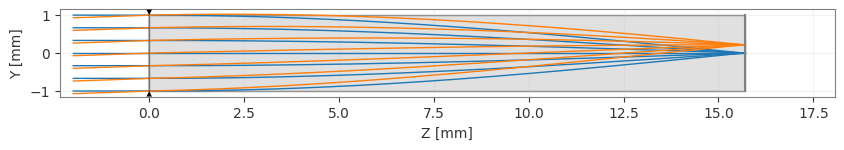

In [3]:
lens = GrinRod()
_ = lens.draw(num_rays=7)

## Check against the analytic pitch

A ray entering parallel to the axis at height $y_0$ reaches the exit face at $y_0 \cos(\sqrt{A} L)$ with slope $-y_0 \sqrt{A} \sin(\sqrt{A} L)$ inside the rod. Tracing rods of several lengths reproduces this. Small differences come from the paraxial approximation, not the integrator.

In [4]:
A, y0 = 0.01, 0.05
print(f"{'pitch':>6} {'traced y':>12} {'analytic y':>12}")
for fraction in (0.125, 0.25, 0.375, 0.5):
    rod = GrinRod(A=A, pitch_fraction=fraction)
    rod.trace_generic(0.0, 0.0, 0.0, y0, 0.55)  # Py = y0 / (EPD / 2)
    traced = float(rod.surfaces[2].y[0])
    analytic = y0 * np.cos(fraction * 2 * np.pi)
    print(f"{fraction:>6} {traced:>12.6f} {analytic:>12.6f}")

 pitch     traced y   analytic y
 0.125     0.035356     0.035355
  0.25    -0.000001     0.000000
 0.375    -0.035357    -0.035355


   0.5    -0.050000    -0.050000


## Spot at the exit face

The quarter-pitch rod images the collimated beam onto its exit face. The remaining blur is the spherical aberration of the truncated parabolic profile.

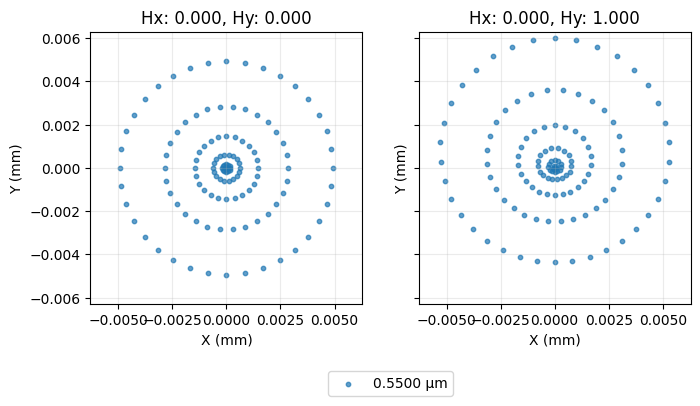

In [5]:
spot = SpotDiagram(lens)
_ = spot.view()

First-order (paraxial) quantities that cross the GRIN medium, such as the exit pupil, are not yet supported and raise `NotImplementedError`; use real-ray analyses like the ones above.